# Mini Project 2: Digit Lab

## Can a plain neural network read handwriting, and how does it fail?

I train a **fully connected neural network** on MNIST and then examine it closely: how accurate it is, where it fails, and what it has learned.

### Required parts
| Requirement | Section |
|-------------|---------|
| Predict digits 0-9 | Parts 2-3 |
| Display sample predictions | Part 5 |
| Test accuracy and confusion matrix | Part 4 |
| At least five wrong predictions with reasons | Part 5 |

### My extra experiments
1. What does each hidden neuron look for?
2. Does the network know when it is unsure?
3. Stress test: how does it compare with my CNN from Week 1?

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.14.1
Using device: mps


## Part 1: The Data

MNIST has 70,000 grayscale images (28x28) of handwritten digits. I split the 60,000 training images into **54,000 for training** and **6,000 for validation** (used to choose settings). The official **10,000 test images** are only used at the end.

In [2]:
MEAN, STD = 0.1307, 0.3081
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.MNIST("data", train=True, download=True, transform=tf)
test_set = datasets.MNIST("data", train=False, download=True, transform=tf)

train_set, val_set = random_split(full_train, [54000, 6000], generator=torch.Generator().manual_seed(42))

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH)
test_loader = DataLoader(test_set, batch_size=BATCH)

print("train / val / test:", len(train_set), "/", len(val_set), "/", len(test_set))

train / val / test: 54000 / 6000 / 10000


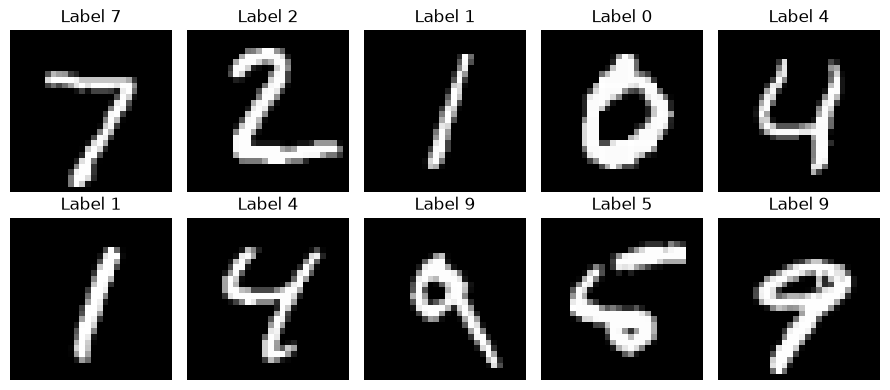

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, i in zip(axes.flat, range(10)):
    img, label = test_set[i]
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")   # undo normalization so it looks normal
    ax.set_title(f"Label {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part 2: The Fully Connected Network

Architecture: **784 → 256 → 128 → 10**
- Each 28x28 image is flattened into 784 numbers
- Two hidden layers (256 and 128 neurons) with **ReLU** and **dropout**
- 10 output scores, one for each digit
- Loss: **cross-entropy**, optimizer: **Adam**

In [4]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128), dropout=0.2):
        super().__init__()
        layers = [nn.Flatten()]
        prev = 28 * 28
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 10))          # 10 outputs, one per digit
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


demo = MLP()
print(demo)
print("Parameters:", sum(p.numel() for p in demo.parameters()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 235146


In [5]:
import copy


def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total


def train_mlp(hidden=(256, 128), dropout=0.2, lr=1e-3, epochs=10, verbose=True):
    torch.manual_seed(0)
    model = MLP(hidden, dropout).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)

        hist["train_loss"].append(tl)
        hist["val_loss"].append(vl)
        hist["train_acc"].append(ta)
        hist["val_acc"].append(va)

        if va > best_acc:                                  # keep the best epoch
            best_acc, best_state = va, copy.deepcopy(model.state_dict())

        if verbose:
            print(f"Epoch {ep:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")

    model.load_state_dict(best_state)
    return model, hist, best_acc

In [6]:
model, hist, best_val = train_mlp()
print(f"\nBest validation accuracy: {best_val:.4f}")

Epoch  1/10 | train loss 0.3305 acc 0.9010 | val loss 0.1536 acc 0.9522
Epoch  2/10 | train loss 0.1403 acc 0.9576 | val loss 0.1130 acc 0.9690
Epoch  3/10 | train loss 0.1026 acc 0.9692 | val loss 0.0935 acc 0.9717
Epoch  4/10 | train loss 0.0820 acc 0.9740 | val loss 0.1090 acc 0.9663
Epoch  5/10 | train loss 0.0698 acc 0.9778 | val loss 0.0801 acc 0.9770
Epoch  6/10 | train loss 0.0631 acc 0.9794 | val loss 0.0798 acc 0.9785
Epoch  7/10 | train loss 0.0555 acc 0.9820 | val loss 0.0811 acc 0.9775
Epoch  8/10 | train loss 0.0506 acc 0.9835 | val loss 0.0793 acc 0.9770
Epoch  9/10 | train loss 0.0463 acc 0.9853 | val loss 0.0697 acc 0.9798
Epoch 10/10 | train loss 0.0417 acc 0.9870 | val loss 0.0722 acc 0.9798

Best validation accuracy: 0.9798


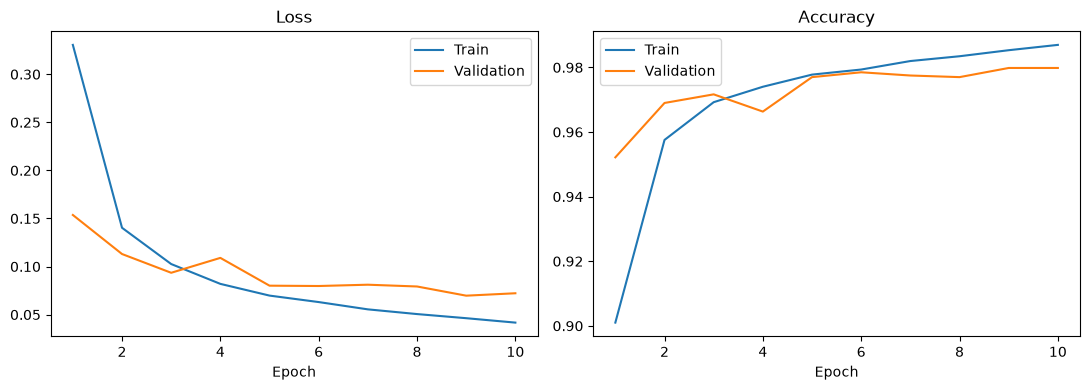

In [7]:
epochs_range = range(1, len(hist["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(epochs_range, hist["train_loss"], label="Train")
ax[0].plot(epochs_range, hist["val_loss"], label="Validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(epochs_range, hist["train_acc"], label="Train")
ax[1].plot(epochs_range, hist["val_acc"], label="Validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## Part 3: Choosing Settings with Validation Data

I train 7 versions of the network for 6 epochs each, changing the **hidden-layer size**, **dropout** and **learning rate**. I compare them on **validation accuracy** and choose the best one. The **gap** (train accuracy minus validation accuracy) shows underfitting or overfitting. The test set is not used here.

In [8]:
configs = [
    ("tiny (16)",         dict(hidden=(16,),      dropout=0.0, lr=1e-3)),
    ("small (64)",        dict(hidden=(64,),      dropout=0.0, lr=1e-3)),
    ("base (256-128)",    dict(hidden=(256, 128), dropout=0.2, lr=1e-3)),
    ("wide (512-256)",    dict(hidden=(512, 256), dropout=0.2, lr=1e-3)),
    ("wide, no dropout",  dict(hidden=(512, 256), dropout=0.0, lr=1e-3)),
    ("base, lr = 0.01",   dict(hidden=(256, 128), dropout=0.2, lr=1e-2)),
    ("base, lr = 0.0001", dict(hidden=(256, 128), dropout=0.2, lr=1e-4)),
]

loss_fn = nn.CrossEntropyLoss()
sweep = []

for name, cfg in configs:
    m, h, best_val_acc = train_mlp(**cfg, epochs=6, verbose=False)
    params = sum(p.numel() for p in m.parameters())
    clean_train_acc = run_epoch(m, train_loader, loss_fn)[1]   # eval mode, no dropout
    sweep.append({"name": name, "cfg": cfg, "params": params,
                  "train": clean_train_acc, "val": best_val_acc})
    print("done:", name)

done: tiny (16)
done: small (64)
done: base (256-128)
done: wide (512-256)
done: wide, no dropout
done: base, lr = 0.01
done: base, lr = 0.0001


In [9]:
print(f"{'setting':<20}{'params':>10}{'train acc':>12}{'val acc':>10}{'gap':>8}")
for r in sweep:
    print(f"{r['name']:<20}{r['params']:>10,}{r['train']:>12.4f}{r['val']:>10.4f}{r['train'] - r['val']:>8.4f}")

best = max(sweep, key=lambda r: r["val"])
print("\nBest by validation accuracy:", best["name"], f"({best['val']:.4f})")

setting                 params   train acc   val acc     gap
tiny (16)               12,730      0.9479    0.9343  0.0136
small (64)              50,890      0.9839    0.9687  0.0153
base (256-128)         235,146      0.9897    0.9785  0.0112
wide (512-256)         535,818      0.9914    0.9780  0.0134
wide, no dropout       535,818      0.9922    0.9762  0.0161
base, lr = 0.01        235,146      0.9620    0.9562  0.0058
base, lr = 0.0001      235,146      0.9627    0.9513  0.0113

Best by validation accuracy: base (256-128) (0.9785)


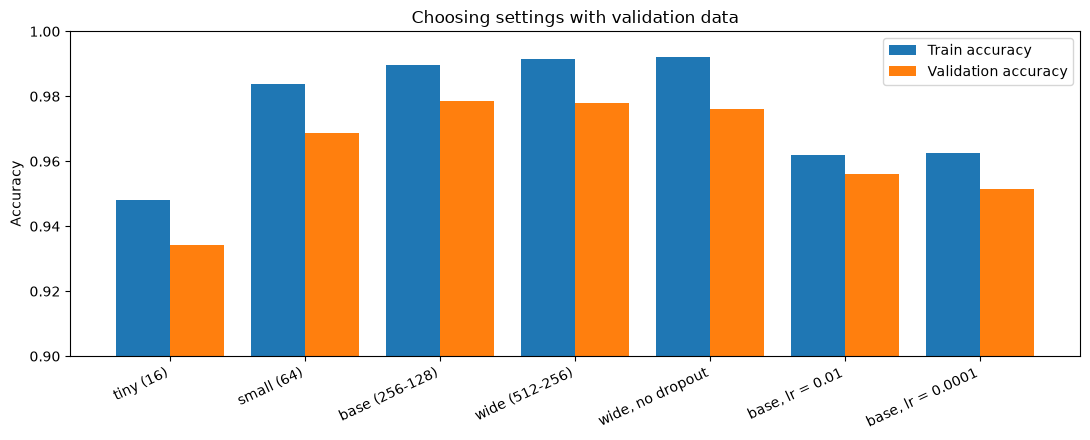

In [10]:
names = [r["name"] for r in sweep]
x = np.arange(len(sweep))

plt.figure(figsize=(11, 4.5))
plt.bar(x - 0.2, [r["train"] for r in sweep], width=0.4, label="Train accuracy")
plt.bar(x + 0.2, [r["val"] for r in sweep], width=0.4, label="Validation accuracy")
plt.xticks(x, names, rotation=25, ha="right")
plt.ylim(0.90, 1.0)
plt.ylabel("Accuracy")
plt.title("Choosing settings with validation data")
plt.legend()
plt.tight_layout()
plt.savefig("settings_comparison.png", dpi=150)
plt.show()

In [11]:
final_model, final_hist, final_val = train_mlp(**best["cfg"], epochs=10, verbose=False)
print("Final model:", best["name"])
print("Best validation accuracy:", round(final_val, 4))

Final model: base (256-128)
Best validation accuracy: 0.9798


### What the results show

- **Underfitting:** the tiny network (16 neurons) has the lowest accuracy on both train and validation, so it is too small to learn the digits well.
- **More capacity helps:** the larger networks reach higher validation accuracy.
- **Overfitting:** the wide network without dropout has the highest training accuracy and a bigger train-validation gap, so it starts to memorize the training set. Dropout reduces this gap.
- **Learning rate:** a very small rate (0.0001) learns slowly in 6 epochs, and a large rate (0.01) is less stable than 0.001.
- **Decision:** I chose the setting with the best **validation accuracy**, and the test set stays untouched until the final evaluation.

## Part 4: Final Test Results

The test set (10,000 images) was not used for training or for choosing settings. I evaluate the chosen network on it once, and report **test accuracy**, **precision / recall / F1 for each digit**, and the **confusion matrix**.

In [12]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    probs, labels, images = [], [], []
    for xb, yb in loader:
        out = model(xb.to(device))
        probs.append(torch.softmax(out, dim=1).cpu())
        labels.append(yb)
        images.append(xb)
    return torch.cat(probs), torch.cat(labels), torch.cat(images)


test_probs, test_labels, test_images = predict_all(final_model, test_loader)
test_preds = test_probs.argmax(1)
test_acc = (test_preds == test_labels).float().mean().item()

print(f"Test accuracy: {test_acc * 100:.2f}%")
print("Wrong predictions:", int((test_preds != test_labels).sum()), "out of", len(test_labels))

Test accuracy: 98.33%
Wrong predictions: 167 out of 10000


In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(test_labels, test_preds, digits=4))

              precision    recall  f1-score   support

           0     0.9858    0.9918    0.9888       980
           1     0.9895    0.9956    0.9925      1135
           2     0.9902    0.9748    0.9824      1032
           3     0.9822    0.9822    0.9822      1010
           4     0.9817    0.9827    0.9822       982
           5     0.9865    0.9854    0.9860       892
           6     0.9793    0.9875    0.9834       958
           7     0.9852    0.9728    0.9790      1028
           8     0.9726    0.9836    0.9781       974
           9     0.9791    0.9762    0.9777      1009

    accuracy                         0.9833     10000
   macro avg     0.9832    0.9833    0.9832     10000
weighted avg     0.9833    0.9833    0.9833     10000



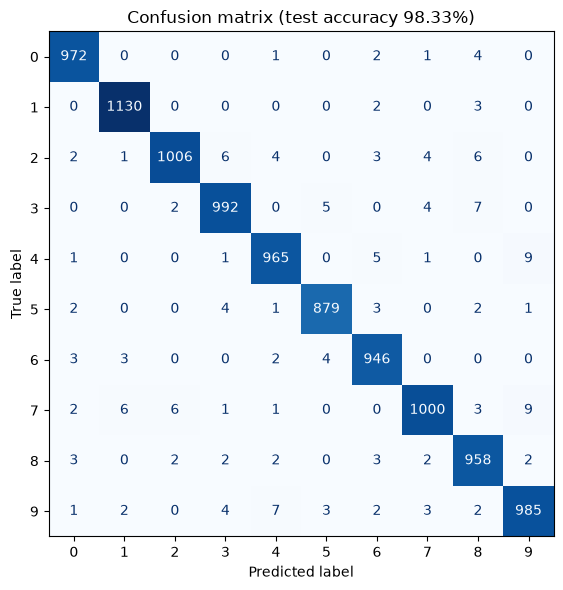

In [14]:
cm = confusion_matrix(test_labels, test_preds)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix (test accuracy {test_acc * 100:.2f}%)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [15]:
pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            pairs.append((int(cm[i, j]), i, j))
pairs.sort(reverse=True)

print("Most common mistakes (true digit -> predicted digit):")
for count, t, p in pairs[:6]:
    print(f"  {t} predicted as {p}: {count} times")

Most common mistakes (true digit -> predicted digit):
  7 predicted as 9: 9 times
  4 predicted as 9: 9 times
  9 predicted as 4: 7 times
  3 predicted as 8: 7 times
  7 predicted as 2: 6 times
  7 predicted as 1: 6 times


## Part 5: Sample Predictions and Error Analysis

First a random sample of test predictions (green = correct, red = wrong, with the model's confidence). Then the **mistakes**: I look at the wrong predictions where the model was **most confident**, and I measure what is different about the images it gets wrong.

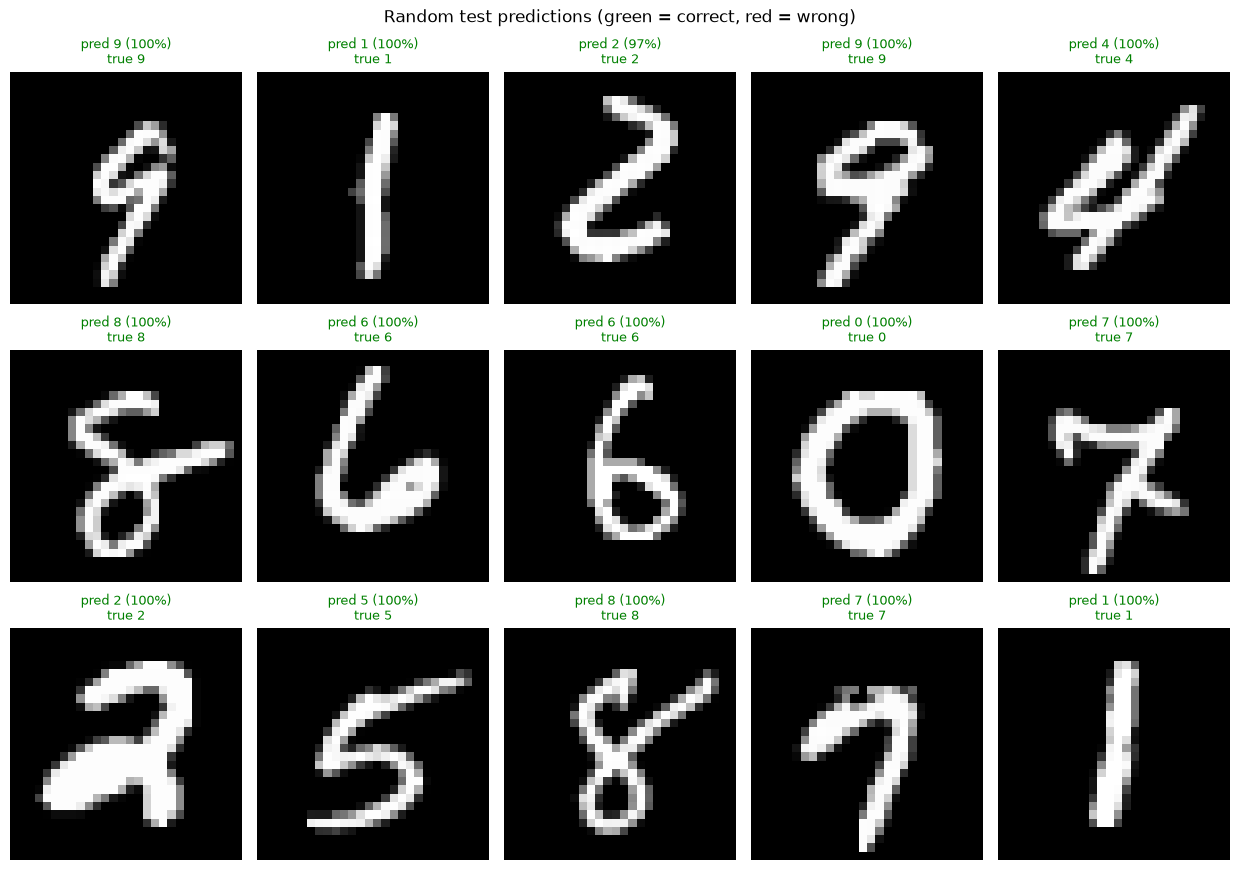

In [16]:
def show_grid(indices, title, filename, cols=5, detail=False):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.5 * cols, 3.0 * rows))
    flat = np.array(axes).flatten()
    for ax, i in zip(flat, indices):
        pred, true = int(test_preds[i]), int(test_labels[i])
        conf = test_probs[i, pred].item()
        ax.imshow(test_images[i].squeeze() * STD + MEAN, cmap="gray")
        if detail:   # for mistakes: show how much probability the TRUE digit got
            ax.set_title(f"pred {pred} ({conf*100:.0f}%)\ntrue {true} ({test_probs[i, true].item()*100:.0f}%)",
                         color="red", fontsize=9)
        else:
            ax.set_title(f"pred {pred} ({conf*100:.0f}%)\ntrue {true}",
                         color="green" if pred == true else "red", fontsize=9)
        ax.axis("off")
    for ax in flat[len(indices):]:
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()


rng = np.random.default_rng(7)
sample_idx = rng.choice(len(test_labels), 15, replace=False)
show_grid(sample_idx, "Random test predictions (green = correct, red = wrong)", "sample_predictions.png")

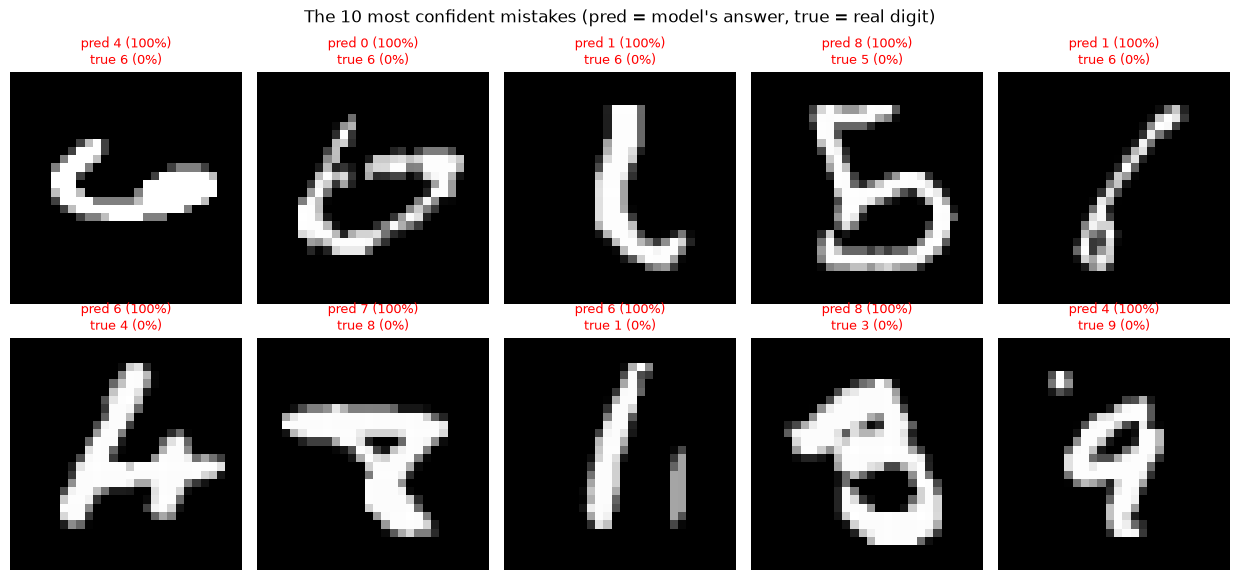

In [17]:
wrong_idx = torch.where(test_preds != test_labels)[0]
wrong_conf = test_probs[wrong_idx, test_preds[wrong_idx]]
top_wrong = wrong_idx[wrong_conf.argsort(descending=True)][:10].tolist()

show_grid(top_wrong, "The 10 most confident mistakes (pred = model's answer, true = real digit)",
          "wrong_predictions.png", detail=True)

In [18]:
raw = test_images * STD + MEAN                 # back to normal 0-1 pixel values
ink = raw.flatten(1).mean(1)                   # average brightness = how much "ink" is in the image
correct = test_preds == test_labels
conf_all = test_probs.max(1).values

print(f"Average confidence | correct: {conf_all[correct].mean():.3f} | wrong: {conf_all[~correct].mean():.3f}")
print(f"Average ink amount | correct: {ink[correct].mean():.3f} | wrong: {ink[~correct].mean():.3f}")
print(f"Wrong predictions made with more than 90% confidence: "
      f"{(conf_all[~correct] > 0.9).sum().item()} of {(~correct).sum().item()}")

per_digit = []
for d in range(10):
    m = test_labels == d
    per_digit.append((1 - (test_preds[m] == d).float().mean().item(), d))
per_digit.sort(reverse=True)
print("\nHardest digits (error rate):")
for err, d in per_digit[:4]:
    print(f"  digit {d}: {err * 100:.2f}%")

Average confidence | correct: 0.991 | wrong: 0.758
Average ink amount | correct: 0.133 | wrong: 0.128
Wrong predictions made with more than 90% confidence: 50 of 167

Hardest digits (error rate):
  digit 7: 2.72%
  digit 2: 2.52%
  digit 9: 2.38%
  digit 3: 1.78%


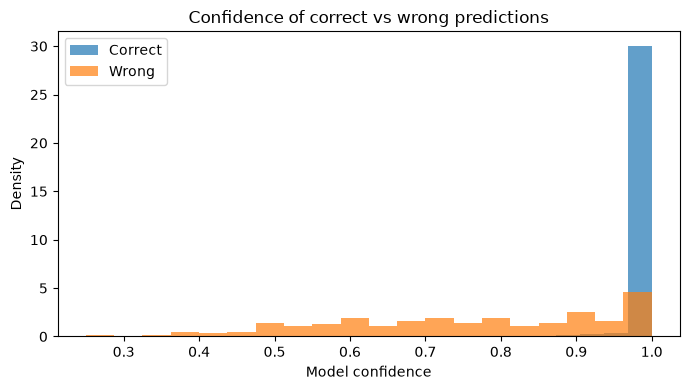

In [19]:
plt.figure(figsize=(7, 4))
plt.hist(conf_all[correct].numpy(), bins=20, alpha=0.7, label="Correct", density=True)
plt.hist(conf_all[~correct].numpy(), bins=20, alpha=0.7, label="Wrong", density=True)
plt.xlabel("Model confidence")
plt.ylabel("Density")
plt.title("Confidence of correct vs wrong predictions")
plt.legend()
plt.tight_layout()
plt.savefig("confidence_hist.png", dpi=150)
plt.show()

In [20]:
from IPython.display import Markdown, display

n_wrong = int((~correct).sum())
conf_ok = conf_all[correct].mean().item()
conf_bad = conf_all[~correct].mean().item()
ink_ok = ink[correct].mean().item()
ink_bad = ink[~correct].mean().item()
high_conf_wrong = int((conf_all[~correct] > 0.9).sum())
top_pairs = ", ".join(f"{t} read as {p} ({c} times)" for c, t, p in pairs[:3])
worst_err, worst_digit = per_digit[0]
ink_word = "more" if ink_bad > ink_ok else "less"

text = f"""
### Error analysis (numbers computed from my own results)

- The network made **{n_wrong}** mistakes on 10,000 test images (**{test_acc * 100:.2f}%** accuracy).
- Average confidence is **{conf_ok:.2f}** on correct predictions and **{conf_bad:.2f}** on wrong ones.
- **{high_conf_wrong}** of the mistakes were made with more than 90% confidence.
- Most frequent confusions: **{top_pairs}**.
- The hardest digit is **{worst_digit}**, with an error rate of **{worst_err * 100:.2f}%**.
- Wrongly classified images have on average **{ink_word}** ink than correctly classified ones ({ink_bad:.3f} vs {ink_ok:.3f}).
"""
display(Markdown(text))


### Error analysis (numbers computed from my own results)

- The network made **167** mistakes on 10,000 test images (**98.33%** accuracy).
- Average confidence is **0.99** on correct predictions and **0.76** on wrong ones.
- **50** of the mistakes were made with more than 90% confidence.
- Most frequent confusions: **7 read as 9 (9 times), 4 read as 9 (9 times), 9 read as 4 (7 times)**.
- The hardest digit is **7**, with an error rate of **2.72%**.
- Wrongly classified images have on average **less** ink than correctly classified ones (0.128 vs 0.133).


### Possible reasons for the mistakes

Looking at the most confident mistakes above, these are the likely causes:

1. **Ambiguous handwriting:** some digits are drawn so sloppily that they sit between two classes, for example a 4 with a closed top looks like a 9. Even a person would hesitate.
2. **Similar shapes:** the most frequent confusions listed above are digits that share strokes and loops.
3. **No sense of shape:** a fully connected network flattens the image into 784 separate numbers, so it does not know which pixels are neighbours. Small shifts, slants or stroke thickness can confuse it. A CNN handles this better, and I test this in Part 7.
4. **Unusual writing styles:** very thin, very thick or unusually shaped digits appear less often in the training data, so the network has seen fewer examples of them.
5. **Overconfidence:** softmax can give a high probability to a wrong answer, so confidence is helpful but not a guarantee of correctness.
6. **Hard or mislabeled images:** MNIST contains a small number of images that are unclear or arguably mislabeled, which no model can get right.

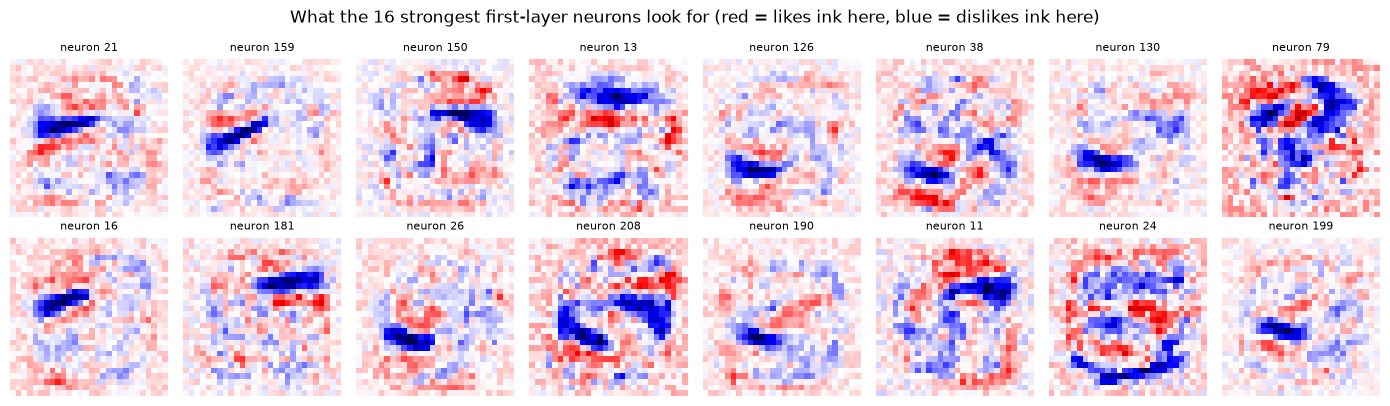

In [21]:
W = final_model.net[1].weight.detach().cpu()           # first Linear layer: (neurons, 784)
strongest = W.norm(dim=1).argsort(descending=True)[:16]

fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax in axes.flat:
    ax.axis("off")
for ax, k in zip(axes.flat, strongest):
    w = W[k].reshape(28, 28)
    lim = w.abs().max()
    ax.imshow(w, cmap="seismic", vmin=-lim, vmax=lim)
    ax.set_title(f"neuron {int(k)}", fontsize=8)

plt.suptitle("What the 16 strongest first-layer neurons look for (red = likes ink here, blue = dislikes ink here)")
plt.tight_layout()
plt.savefig("neuron_weight_maps.png", dpi=150)
plt.show()

### 6B. Does the network know when it is unsure?
If the network only answers when its confidence is above a threshold, how accurate is it, and how many digits does it still answer?

 confidence >=   answers   accuracy
           0.0    100.0%     98.33%
           0.5     99.7%     98.50%
           0.7     98.4%     98.94%
           0.9     96.3%     99.48%
          0.95     95.0%     99.64%
          0.99     91.0%     99.80%
         0.999     81.7%     99.94%


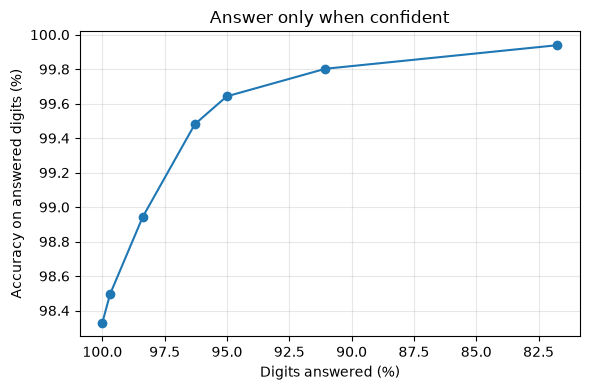

In [22]:
thresholds = [0.0, 0.5, 0.7, 0.9, 0.95, 0.99, 0.999]
rows = []
for t in thresholds:
    keep = conf_all >= t
    coverage = keep.float().mean().item()
    acc = correct[keep].float().mean().item() if keep.any() else float("nan")
    rows.append((t, coverage, acc))

print(f"{'confidence >=':>14}{'answers':>10}{'accuracy':>11}")
for t, cov, acc in rows:
    print(f"{t:>14}{cov * 100:>9.1f}%{acc * 100:>10.2f}%")

plt.figure(figsize=(6, 4))
plt.plot([r[1] * 100 for r in rows], [r[2] * 100 for r in rows], marker="o")
plt.xlabel("Digits answered (%)")
plt.ylabel("Accuracy on answered digits (%)")
plt.title("Answer only when confident")
plt.gca().invert_xaxis()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("confidence_tradeoff.png", dpi=150)
plt.show()

**Observation:** the more confident the network has to be before answering, the higher its accuracy on the digits it does answer, but the fewer digits it answers. This shows that the confidence score carries real information, so a system could send the uncertain digits to a human instead of guessing.

## Part 7: Stress Test, My Plain Network vs My Week 1 CNN

Real handwriting is shifted, tilted and noisy. I take the 10,000 test images, change them in three ways (**shift sideways**, **add noise**, **rotate**) and score both models on the same changed images:

- **Plain network:** the fully connected network from this project
- **CNN:** the convolutional network I built in Week 1 (99.20% on clean test images)

**Fairness note:** the Week 1 CNN was trained with augmentation (small shifts, rotations and zoom) and this plain network was not, so part of the difference comes from training and not only from the architecture.

In [23]:
import os


class DigitCNN(nn.Module):          # same architecture as Week-01/Mini-Project/model.py
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_path = "../../Week-01/Mini-Project/digit_cnn.pth"
print("Working folder:", os.getcwd())
print("CNN file found:", os.path.exists(cnn_path))

cnn = DigitCNN().to(device)
cnn.load_state_dict(torch.load(cnn_path, map_location=device))
cnn.eval()


@torch.no_grad()
def accuracy_on(model, X, y, bs=1000):
    model.eval()
    ok = 0
    for i in range(0, len(X), bs):
        ok += (model(X[i:i + bs].to(device)).argmax(1).cpu() == y[i:i + bs]).sum().item()
    return ok / len(X)


print(f"Clean test accuracy | plain network: {accuracy_on(final_model, test_images, test_labels) * 100:.2f}%"
      f" | CNN: {accuracy_on(cnn, test_images, test_labels) * 100:.2f}%")

Working folder: /Users/bhoomikamt/Documents/Deep-Learning-AI-Internship/Week-02/Mini-Project
CNN file found: True
Clean test accuracy | plain network: 98.33% | CNN: 99.20%


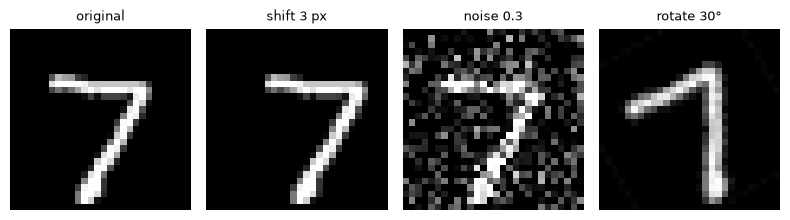

In [24]:
import torchvision.transforms.functional as TF

BG = (0 - MEAN) / STD        # the value of a black background pixel after normalization


def shift_images(x, dx, dy=0):
    out = torch.full_like(x, BG)
    sx0, sx1 = max(0, -dx), min(28, 28 - dx)
    sy0, sy1 = max(0, -dy), min(28, 28 - dy)
    out[:, :, sy0 + dy:sy1 + dy, sx0 + dx:sx1 + dx] = x[:, :, sy0:sy1, sx0:sx1]
    return out


def add_noise(x, sigma):
    g = torch.Generator().manual_seed(1)
    raw = (x * STD + MEAN) + sigma * torch.randn(x.shape, generator=g)
    return (raw.clamp(0, 1) - MEAN) / STD


def rotate_images(x, angle):
    if angle == 0:
        return x
    return TF.rotate(x, float(angle), interpolation=transforms.InterpolationMode.BILINEAR, fill=[BG])


sample = test_images[:1]
variants = [("original", sample), ("shift 3 px", shift_images(sample, 3)),
            ("noise 0.3", add_noise(sample, 0.3)), ("rotate 30°", rotate_images(sample, 30))]

fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for ax, (name, img) in zip(axes, variants):
    ax.imshow(img[0, 0] * STD + MEAN, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [25]:
levels = {
    "Shift (pixels)":     [0, 1, 2, 3, 4, 5],
    "Noise (strength)":   [0.0, 0.1, 0.2, 0.3, 0.4, 0.5],
    "Rotation (degrees)": [0, 10, 20, 30, 40],
}


def make_variant(kind, level):
    if kind == "Shift (pixels)":
        return shift_images(test_images, int(level))
    if kind == "Noise (strength)":
        return add_noise(test_images, level)
    return rotate_images(test_images, level)


stress = {}
for kind, lv in levels.items():
    stress[kind] = []
    for level in lv:
        xv = make_variant(kind, level)
        stress[kind].append((level, accuracy_on(final_model, xv, test_labels), accuracy_on(cnn, xv, test_labels)))

    print(f"\n{kind}")
    print(f"{'level':>8}{'plain network':>16}{'CNN':>9}")
    for level, a_mlp, a_cnn in stress[kind]:
        print(f"{level:>8}{a_mlp * 100:>15.2f}%{a_cnn * 100:>8.2f}%")


Shift (pixels)
   level   plain network      CNN
       0          98.33%   99.20%
       1          96.60%   99.18%
       2          86.53%   99.02%
       3          63.27%   98.85%
       4          39.94%   98.12%
       5          22.12%   95.84%

Noise (strength)
   level   plain network      CNN
     0.0          98.33%   99.20%
     0.1          98.06%   98.83%
     0.2          97.29%   79.51%
     0.3          95.25%   22.86%
     0.4          88.98%   10.42%
     0.5          77.18%    9.76%

Rotation (degrees)
   level   plain network      CNN
       0          98.33%   99.20%
      10          97.13%   98.55%
      20          91.56%   95.65%
      30          78.31%   86.76%
      40          59.53%   69.28%


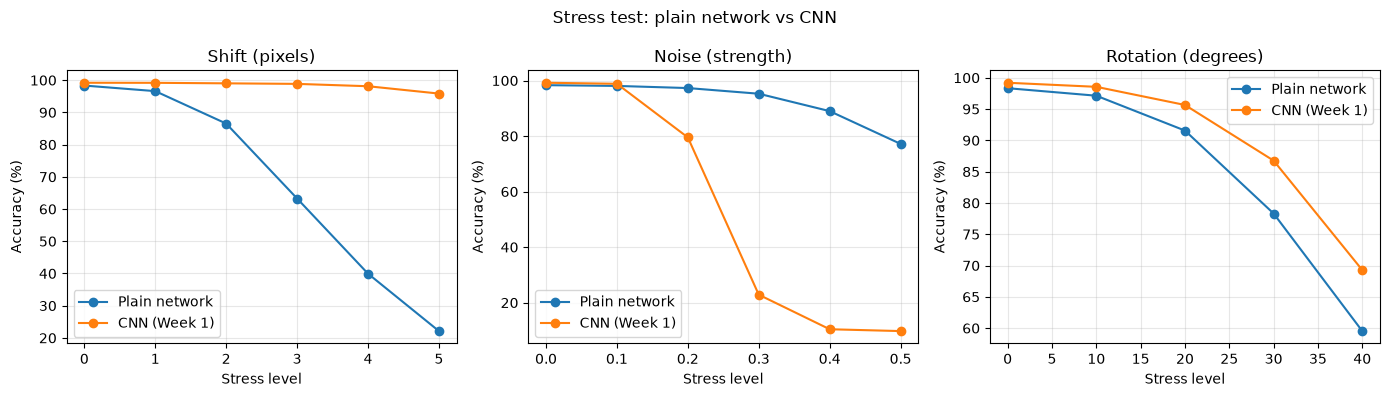

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (kind, rows) in zip(axes, stress.items()):
    xs = [r[0] for r in rows]
    ax.plot(xs, [r[1] * 100 for r in rows], marker="o", label="Plain network")
    ax.plot(xs, [r[2] * 100 for r in rows], marker="o", label="CNN (Week 1)")
    ax.set_title(kind)
    ax.set_xlabel("Stress level")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Stress test: plain network vs CNN")
plt.tight_layout()
plt.savefig("stress_test.png", dpi=150)
plt.show()

In [27]:
lines = []
for kind, rows in stress.items():
    first, last = rows[0], rows[-1]
    drop_mlp = (first[1] - last[1]) * 100
    drop_cnn = (first[2] - last[2]) * 100
    winner = "CNN" if drop_cnn < drop_mlp else "plain network"
    lines.append(
        f"- **{kind}**, hardest level ({last[0]}): plain network **{last[1] * 100:.1f}%** "
        f"(lost {drop_mlp:.1f} points), CNN **{last[2] * 100:.1f}%** (lost {drop_cnn:.1f} points). "
        f"More robust here: **{winner}**."
    )

summary = "### What the stress test shows\n\n" + "\n".join(lines) + """

**Why:** the plain network treats every pixel as an independent input, so moving the digit changes almost all of its input numbers. The CNN slides the same small filters over the whole image, so it finds the same strokes wherever they are. Remember that the CNN also had augmentation during training, which helps it with shifts and rotations.
"""
display(Markdown(summary))

### What the stress test shows

- **Shift (pixels)**, hardest level (5): plain network **22.1%** (lost 76.2 points), CNN **95.8%** (lost 3.4 points). More robust here: **CNN**.
- **Noise (strength)**, hardest level (0.5): plain network **77.2%** (lost 21.1 points), CNN **9.8%** (lost 89.4 points). More robust here: **plain network**.
- **Rotation (degrees)**, hardest level (40): plain network **59.5%** (lost 38.8 points), CNN **69.3%** (lost 29.9 points). More robust here: **CNN**.

**Why:** the plain network treats every pixel as an independent input, so moving the digit changes almost all of its input numbers. The CNN slides the same small filters over the whole image, so it finds the same strokes wherever they are. Remember that the CNN also had augmentation during training, which helps it with shifts and rotations.


In [28]:
s = stress["Shift (pixels)"][-1]

conclusion = f"""
## Part 8: Conclusion

- **Result:** a fully connected network (**{best['name']}**) reads handwritten digits with **{test_acc * 100:.2f}%** accuracy on 10,000 test images that were never used for training or for choosing settings.
- **Choosing settings:** I compared 7 settings on validation data. A network that is too small underfits, and a large one without dropout starts to overfit, so I picked the best validation score.
- **Where it fails:** {n_wrong} test images were wrong. Most frequent confusions: {top_pairs}. The hardest digit was {worst_digit}.
- **Confidence is useful:** wrong predictions have lower confidence on average ({conf_bad:.2f} vs {conf_ok:.2f}), so a system could refuse to answer when unsure.
- **Limit of a plain network:** with a {s[0]}-pixel shift it scores {s[1] * 100:.1f}%, while my Week 1 CNN scores {s[2] * 100:.1f}%. Flattening the image throws away the neighbourhood structure that convolutions use.
"""
display(Markdown(conclusion))


## Part 8: Conclusion

- **Result:** a fully connected network (**base (256-128)**) reads handwritten digits with **98.33%** accuracy on 10,000 test images that were never used for training or for choosing settings.
- **Choosing settings:** I compared 7 settings on validation data. A network that is too small underfits, and a large one without dropout starts to overfit, so I picked the best validation score.
- **Where it fails:** 167 test images were wrong. Most frequent confusions: 7 read as 9 (9 times), 4 read as 9 (9 times), 9 read as 4 (7 times). The hardest digit was 7.
- **Confidence is useful:** wrong predictions have lower confidence on average (0.76 vs 0.99), so a system could refuse to answer when unsure.
- **Limit of a plain network:** with a 5-pixel shift it scores 22.1%, while my Week 1 CNN scores 95.8%. Flattening the image throws away the neighbourhood structure that convolutions use.


In [29]:
sw_rows = "\n".join(
    f"| {r['name']} | {r['params']:,} | {r['train'] * 100:.2f}% | {r['val'] * 100:.2f}% | {(r['train'] - r['val']) * 100:.2f} |"
    for r in sweep
)

st_rows = "\n".join(
    f"| {kind} | {rws[-1][0]} | {rws[-1][1] * 100:.1f}% | {rws[-1][2] * 100:.1f}% |"
    for kind, rws in stress.items()
)

readme = f"""# Digit Lab: A Fully Connected Neural Network on MNIST

Week 2 mini project of the Deep Learning & AI Internship (NEXIS Solutions).

A fully connected neural network (784 -> hidden layers -> 10) is trained to recognize handwritten digits from MNIST. Besides the required test metrics, the project examines how the network fails, what its neurons look for, how its confidence behaves, and how it compares with the CNN from Week 1 when digits are shifted, noisy or rotated.

## Results

| Metric | Value |
|--------|-------|
| **Test accuracy** | **{test_acc * 100:.2f}%** |
| Chosen setting | {best['name']} |
| Best validation accuracy | {final_val * 100:.2f}% |
| Wrong test predictions | {n_wrong} of 10,000 |

## Required features

| Requirement | Where |
|-------------|-------|
| Predict digits 0-9 | Parts 2-3 |
| Sample predictions | Part 5 (picture below) |
| Test accuracy and confusion matrix | Part 4 |
| At least five wrong predictions with reasons | Part 5 |

## Training curves
![Training curves](training_curves.png)

## Choosing settings with validation data

| Setting | Parameters | Train acc | Validation acc | Gap (points) |
|---------|-----------|-----------|----------------|--------------|
{sw_rows}

![Settings comparison](settings_comparison.png)

## Confusion matrix (10,000 test images)
![Confusion matrix](confusion_matrix.png)

## Sample predictions
![Sample predictions](sample_predictions.png)

## Error analysis

The 10 most confident mistakes:

![Wrong predictions](wrong_predictions.png)

- Average confidence: {conf_ok:.2f} when correct, {conf_bad:.2f} when wrong.
- {high_conf_wrong} of the {n_wrong} mistakes were made with more than 90% confidence.
- Most frequent confusions: {top_pairs}.
- Hardest digit: {worst_digit} ({worst_err * 100:.2f}% error rate).
- Likely reasons: ambiguous or sloppy handwriting, digits with similar shapes, no sense of pixel neighbourhood in a fully connected network, unusual writing styles, and a few unclear or mislabeled images.

![Confidence histogram](confidence_hist.png)

## Extra experiments

### What each hidden neuron looks for
![Neuron weight maps](neuron_weight_maps.png)

### Does the network know when it is unsure?
![Confidence trade-off](confidence_tradeoff.png)

### Stress test: plain network vs Week 1 CNN

| Test | Hardest level | Plain network | CNN |
|------|---------------|---------------|-----|
{st_rows}

![Stress test](stress_test.png)

The Week 1 CNN was trained with augmentation and this network was not, so part of the gap comes from training as well as the architecture.

## Run it

From the repository root:

    python -m venv venv
    source venv/bin/activate
    python -m pip install -r Week-01/Mini-Project/requirements.txt ipykernel

Then open `Week-02/Mini-Project/digit_lab.ipynb`, select the `venv` kernel and run all cells. Part 7 loads the Week 1 CNN weights from `Week-01/Mini-Project/digit_cnn.pth`.
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README.md written in:", os.getcwd())

README.md written in: /Users/bhoomikamt/Documents/Deep-Learning-AI-Internship/Week-02/Mini-Project
